Not found (check spelling): []
Filtered out 83 rows; 857 remain

Training on 6 features: ['Steps', 'Total_Distance', 'Very_Active_Minutes', 'Fairly_Active_Minutes', 'Lightly_Active_Minutes', 'Sedentary_Minutes']

Learned 'normal' from 788 days (69 flagged unusual)

=== NORMAL DAILY ACTIVITY PROFILE ===
                        Lowest Normal  Typical Low (25%)  Median  \
Steps                             4.0             4910.0  7803.0   
Total_Distance                    0.0                3.4     5.4   
Very_Active_Minutes               0.0                0.0     6.0   
Fairly_Active_Minutes             0.0                0.0     7.0   
Lightly_Active_Minutes            1.0              149.8   212.0   
Sedentary_Minutes               125.0              726.8  1020.5   

                        Typical High (75%)  Highest Normal  Average  
Steps                              10539.5         18387.0   7834.5  
Total_Distance                         7.5            16.3      5.5  
Very_Acti

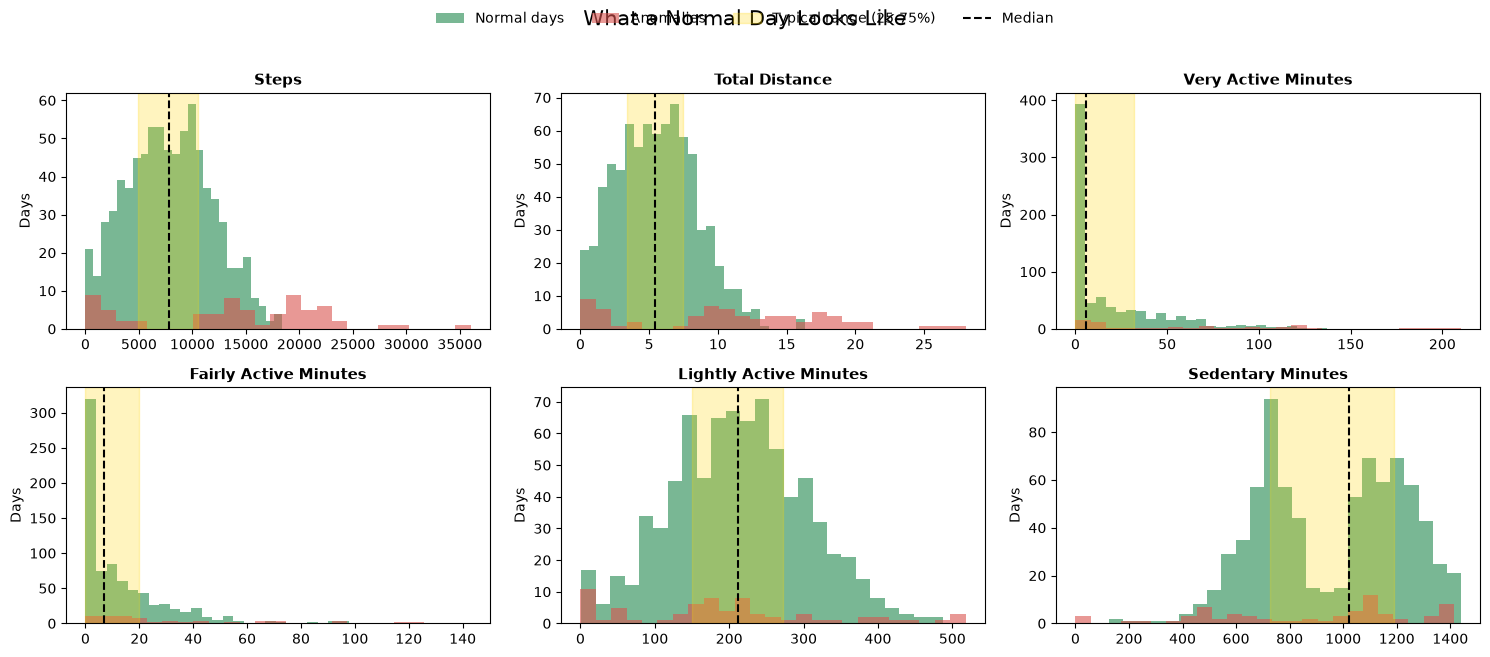

['normal_model.joblib']

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

# 1. Load data
df = pd.read_csv("Activity.xls")

# 2. Remove the user ID and the two distance columns
cols_to_drop = ['UserID', 'Logged_Activities_Distance', 'Sedentary_Active_Distance']
print("Not found (check spelling):", [c for c in cols_to_drop if c not in df.columns])
df = df.drop(columns=cols_to_drop, errors='ignore')

rows_before = len(df)

# 3. FILTER: remove days where the tracker was probably not worn
no_activity = (
    (df['Total_Distance'] == 0) &
    (df['Very_Active_Minutes'] == 0) &
    (df['Lightly_Active_Minutes'] == 0)
)
all_day_sedentary = df['Sedentary_Minutes'] >= 1440
missing_core = df[['Total_Distance', 'Sedentary_Minutes', 'Calories_Burned']].isna().any(axis=1)

df = df[~(no_activity | all_day_sedentary | missing_core)].reset_index(drop=True)
print(f"Filtered out {rows_before - len(df)} rows; {len(df)} remain\n")

# 4. Features = all remaining numeric columns
features = ['Steps', 'Total_Distance', 'Very_Active_Minutes',
            'Fairly_Active_Minutes', 'Lightly_Active_Minutes',
            'Sedentary_Minutes']
print(f"Training on {len(features)} features: {features}\n")
X = df[features].fillna(0)

# 5. Train the model
model = IsolationForest(contamination=0.08, random_state=42)
model.fit(X)
df['ai_verdict'] = model.predict(X)                  # 1 = normal, -1 = anomaly
df['normality_score'] = model.decision_function(X)

normal_days = df[df['ai_verdict'] == 1]
anomalies = df[df['ai_verdict'] == -1]
print(f"Learned 'normal' from {len(normal_days)} days ({len(anomalies)} flagged unusual)\n")

# 6. Normal activity profile
profile = normal_days[features].describe(percentiles=[0.25, 0.5, 0.75]).T
profile = profile[['min', '25%', '50%', '75%', 'max', 'mean']]
profile.columns = ['Lowest Normal', 'Typical Low (25%)', 'Median',
                   'Typical High (75%)', 'Highest Normal', 'Average']
print("=== NORMAL DAILY ACTIVITY PROFILE ===")
print(profile.round(1))

# 7. CHART: one panel per metric
n = len(features)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.2 * rows))
axes = np.array(axes).flatten()

for ax, feat in zip(axes, features):
    lo, med, hi = profile.loc[feat, ['Typical Low (25%)', 'Median', 'Typical High (75%)']]

    ax.hist(normal_days[feat], bins=25, color="#4C9F70", alpha=0.75, label="Normal days")
    ax.hist(anomalies[feat], bins=25, color="#D9534F", alpha=0.6, label="Anomalies")
    ax.axvspan(lo, hi, color="gold", alpha=0.25, label="Typical range (25-75%)")
    ax.axvline(med, color="black", linestyle="--", linewidth=1.5, label="Median")

    ax.set_title(feat.replace("_", " "), fontsize=11, fontweight="bold")
    ax.set_ylabel("Days")

for ax in axes[n:]:
    ax.axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.suptitle("What a Normal Day Looks Like", fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig("normal_activity_profile.png", dpi=150, bbox_inches="tight")
plt.show()

# 8. Check a new day against the learned baseline
def check_day(day: dict):
    new = pd.DataFrame([day])[features].fillna(0)
    return "Normal" if model.predict(new)[0] == 1 else "Unusual"

import joblib
joblib.dump({'model': model, 'features': features,
             'medians': normal_days[features].median().to_dict()},
            'normal_model.joblib')